<a href="https://colab.research.google.com/github/Sahana14082003/AML/blob/main/Lab3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

First Five Records:
    mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst peri

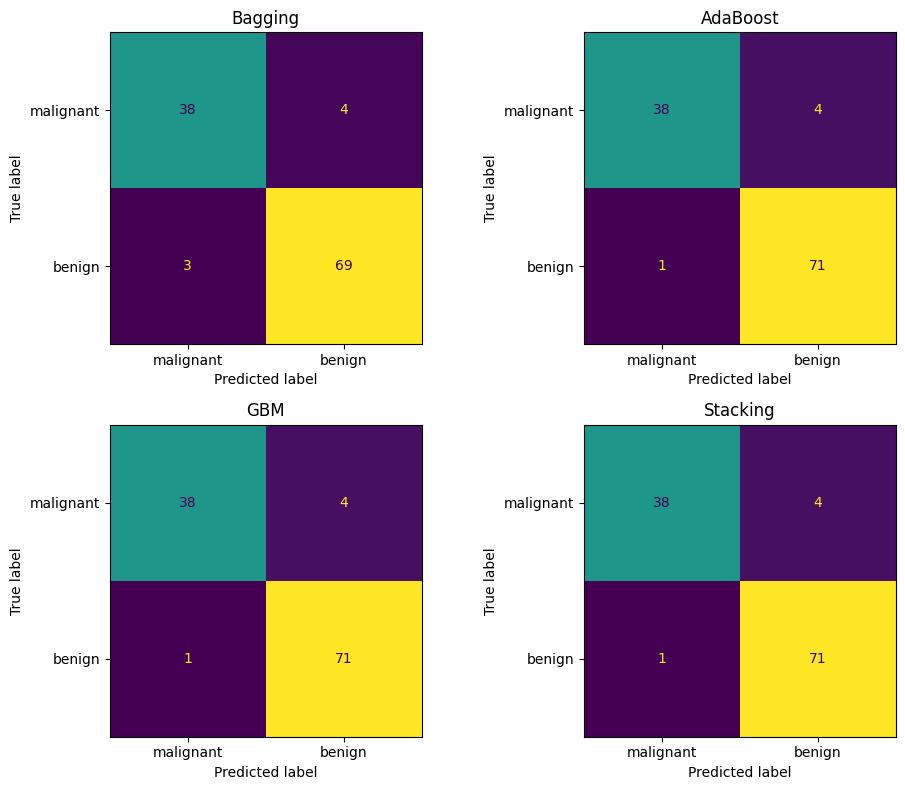

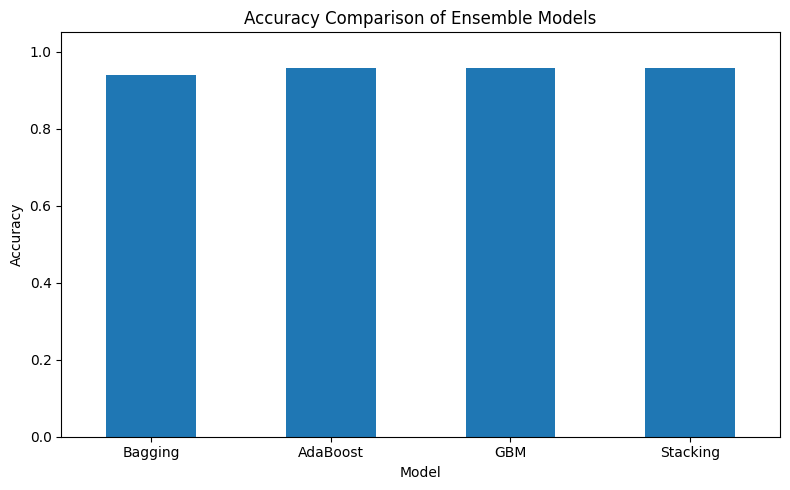

<Figure size 800x600 with 0 Axes>

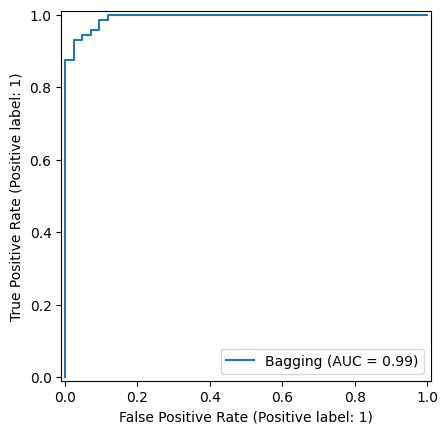

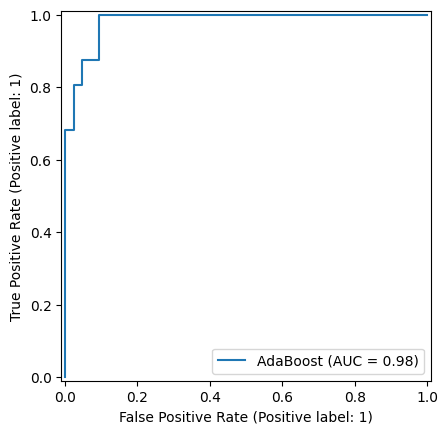

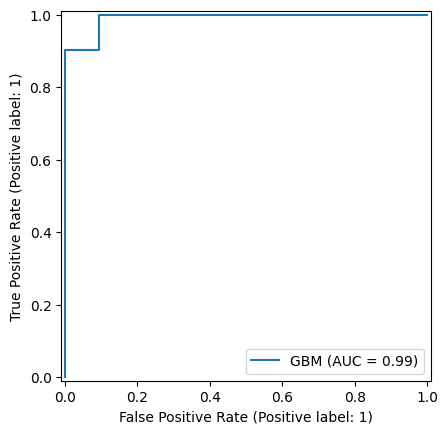

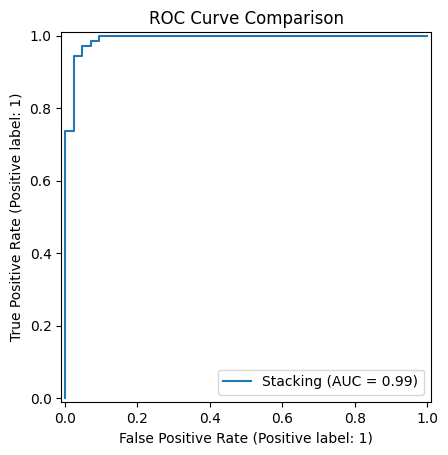

In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (BaggingClassifier, AdaBoostClassifier,
                              GradientBoostingClassifier, RandomForestClassifier,
                              StackingClassifier)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay)

# Load Dataset
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("First Five Records:\n", X.head())
print("\nDataset Shape:", X.shape)

# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Define Ensemble Models
models = {
    "Bagging": BaggingClassifier(
        estimator=DecisionTreeClassifier(),
        n_estimators=100,
        random_state=42
    ),

    "AdaBoost": AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1),
        n_estimators=100,
        random_state=42
    ),

    "GBM": GradientBoostingClassifier(
        n_estimators=100,
        random_state=42
    ),

    "Stacking": StackingClassifier(
        estimators=[
            ("dt", DecisionTreeClassifier(random_state=42)),
            ("rf", RandomForestClassifier(n_estimators=50, random_state=42)),
            ("knn", make_pipeline(StandardScaler(), KNeighborsClassifier()))
        ],
        final_estimator=make_pipeline(
            StandardScaler(), LogisticRegression(max_iter=1000)
        )
    )
}

# Train and Evaluate Models
results = []
predictions = {}
probabilities = {}
train_times = {}
predict_times = {}

for name, model in models.items():

    start = time.time()
    model.fit(X_train, y_train)
    train_times[name] = time.time() - start

    start = time.time()
    y_pred = model.predict(X_test)
    predict_times[name] = time.time() - start

    y_prob = model.predict_proba(X_test)[:, 1]

    predictions[name] = y_pred
    probabilities[name] = y_prob

    results.append([
        name,
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred),
        roc_auc_score(y_test, y_prob)
    ])

# Display Comparison
comparison = pd.DataFrame(results, columns=[
    "Model", "Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"
])

print("\nModel Performance Comparison:\n")
print(comparison.round(4).to_string(index=False))

print("\nTraining and Prediction Time:")
for name in models:
    print(name, "- Training:", round(train_times[name], 4),
          "Prediction:", round(predict_times[name], 4))

# Confusion Matrices
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for ax, name in zip(axes.ravel(), models):
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions[name],
        display_labels=data.target_names,
        ax=ax, colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

# Accuracy Comparison
comparison.plot(
    x="Model", y=["Accuracy"], kind="bar",
    figsize=(8, 5), legend=False
)
plt.title("Accuracy Comparison of Ensemble Models")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# ROC Curves
plt.figure(figsize=(8, 6))

for name in models:
    RocCurveDisplay.from_predictions(
        y_test, probabilities[name], name=name
    )

plt.title("ROC Curve Comparison")
plt.show()
